In [1]:
import os
if os.getenv("CUDA_VISIBLE_DEVICES") is None:
    gpu_num = 2 # Use "" to use the CPU
    os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
    print(f"Using GPU {gpu_num}")
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)
# Avoid warnings from TensorFlow
tf.get_logger().setLevel('ERROR')

import pandas as pd
from data_preprocessing import preprocess_data, preprocess_data_channel
from mlp.mlp_model import train_mlp, train_mlp_channel
from evaluation import print_metrics
from visualization import plot_confusion_matrix, plot_roc_curve


Using GPU 2


E0000 00:00:1747053469.457015 3824020 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1747053469.462745 3824020 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Using GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Full Dataset NLOS/LOS Classification
====================================

In [ ]:
# Load the datasets
# df_tdl_cdl = pd.read_csv("dataset_tdl_cdl_training_siso.csv")
# df_tdl_cdl_test = pd.read_csv("dataset_tdl_cdl_testing.csv")

df_tdl_cdl_siso = pd.read_csv("dataset_tdl_cdl_training_siso.csv")
df_tdl_cdl_siso_test = pd.read_csv("dataset_tdl_cdl_testing.csv")
df_tdl_cdl_mimo = pd.read_csv("dataset_tdl_cdl_training_mimo.csv")
df_tdl_cdl_mimo_test = pd.read_csv("dataset_tdl_cdl_testing_mimo.csv")
df_tdl_cdl_0db_siso_test = pd.read_csv("dataset_tdl_cdl_0db_siso.csv")
df_tdl_cdl_0db_mimo_test = pd.read_csv("dataset_tdl_cdl_0db_mimo.csv")
# 5db
df_tdl_cdl_5db_siso_test = pd.read_csv("dataset_tdl_cdl_5db_siso.csv")
df_tdl_cdl_5db_mimo_test = pd.read_csv("dataset_tdl_cdl_5db_mimo.csv")
# 10db
df_tdl_cdl_10db_siso_test = pd.read_csv("dataset_tdl_cdl_10db_siso.csv")
df_tdl_cdl_10db_mimo_test = pd.read_csv("dataset_tdl_cdl_10db_mimo.csv")
# 15db
df_tdl_cdl_15db_siso_test = pd.read_csv("dataset_tdl_cdl_15db_siso.csv")
df_tdl_cdl_15db_mimo_test = pd.read_csv("dataset_tdl_cdl_15db_mimo.csv")

# df_sionna_mimo_los = pd.read_csv("dataset/dataset_sionna_mimo_los.csv")
# df_sionna_mimo_los_test = pd.read_csv("dataset/dataset_sionna_mimo_los_test.csv")
# df_sionna_mimo_nlos = pd.read_csv("dataset_sionna_mimo_nlos.csv")
# df_sionna_mimo_nlos_test = pd.read_csv("dataset_sionna_mimo_nlos_test.csv")
# df_sionna_siso_los = pd.read_csv("dataset_sionna_siso_los.csv")
# df_sionna_siso_los_test = pd.read_csv("dataset_sionna_siso_los_test.csv")
# df_sionna_siso_nlos = pd.read_csv("temporary_data/dataset_sionna_siso_nlos.csv")
# df_sionna_siso_nlos_test = pd.read_csv("temporary_data/dataset_sionna_siso_nlos_test.csv")


# Make the dataset for tdl only and cdl only (based on the column name model_type)
# df_tdl = df_tdl_cdl[df_tdl_cdl['model_type'] == 'tdl']
# df_cdl = df_tdl_cdl[df_tdl_cdl['model_type'] == 'cdl']
# df_tdl_test = df_tdl_cdl_test[df_tdl_cdl_test['model_type'] == 'tdl']
# df_cdl_test = df_tdl_cdl_test[df_tdl_cdl_test['model_type'] == 'cdl']
# nlos_test.csv")

# # concatenate the datasets
# df_sionna_mimo = pd.concat([df_sionna_mimo_los, df_sionna_mimo_nlos])
# df_sionna_mimo_test = pd.concat([df_sionna_mimo_los_test, df_sionna_mimo_nlos_test])



# # concatenate the datasets
# df_sionna_siso = pd.concat([df_sionna_siso_los, df_sionna_siso_nlos])
# df_sionna_siso_test = pd.concat([df_sionna_siso_los_test, df_sionna_siso_nlos_test])



df_tdl_siso = df_tdl_cdl_siso[df_tdl_cdl_siso['model_type'] == 'tdl']
df_cdl_siso = df_tdl_cdl_siso[df_tdl_cdl_siso['model_type'] == 'cdl']
df_tdl_siso_test = df_tdl_cdl_siso_test[df_tdl_cdl_siso_test['model_type'] == 'tdl']
df_cdl_siso_test = df_tdl_cdl_siso_test[df_tdl_cdl_siso_test['model_type'] == 'cdl']
df_tdl_mimo = df_tdl_cdl_mimo[df_tdl_cdl_mimo['model_type'] == 'tdl']
df_cdl_mimo = df_tdl_cdl_mimo[df_tdl_cdl_mimo['model_type'] == 'cdl']
df_tdl_mimo_test = df_tdl_cdl_mimo_test[df_tdl_cdl_mimo_test['model_type'] == 'tdl']
df_cdl_mimo_test = df_tdl_cdl_mimo_test[df_tdl_cdl_mimo_test['model_type'] == 'cdl']
df_tdl_0db_siso_test = df_tdl_cdl_0db_siso_test[df_tdl_cdl_0db_siso_test['model_type'] == 'tdl']
df_cdl_0db_siso_test = df_tdl_cdl_0db_siso_test[df_tdl_cdl_0db_siso_test['model_type'] == 'cdl']
df_tdl_0db_mimo_test = df_tdl_cdl_0db_mimo_test[df_tdl_cdl_0db_mimo_test['model_type'] == 'tdl']
df_cdl_0db_mimo_test = df_tdl_cdl_0db_mimo_test[df_tdl_cdl_0db_mimo_test['model_type'] == 'cdl']
df_tdl_5db_siso_test = df_tdl_cdl_5db_siso_test[df_tdl_cdl_5db_siso_test['model_type'] == 'tdl']
df_cdl_5db_siso_test = df_tdl_cdl_5db_siso_test[df_tdl_cdl_5db_siso_test['model_type'] == 'cdl']
df_tdl_5db_mimo_test = df_tdl_cdl_5db_mimo_test[df_tdl_cdl_5db_mimo_test['model_type'] == 'tdl']
df_cdl_5db_mimo_test = df_tdl_cdl_5db_mimo_test[df_tdl_cdl_5db_mimo_test['model_type'] == 'cdl']
df_tdl_10db_siso_test = df_tdl_cdl_10db_siso_test[df_tdl_cdl_10db_siso_test['model_type'] == 'tdl']
df_cdl_10db_siso_test = df_tdl_cdl_10db_siso_test[df_tdl_cdl_10db_siso_test['model_type'] == 'cdl']
df_tdl_10db_mimo_test = df_tdl_cdl_10db_mimo_test[df_tdl_cdl_10db_mimo_test['model_type'] == 'tdl']
df_cdl_10db_mimo_test = df_tdl_cdl_10db_mimo_test[df_tdl_cdl_10db_mimo_test['model_type'] == 'cdl']
df_tdl_15db_siso_test = df_tdl_cdl_15db_siso_test[df_tdl_cdl_15db_siso_test['model_type'] == 'tdl']
df_cdl_15db_siso_test = df_tdl_cdl_15db_siso_test[df_tdl_cdl_15db_siso_test['model_type'] == 'cdl']
df_tdl_15db_mimo_test = df_tdl_cdl_15db_mimo_test[df_tdl_cdl_15db_mimo_test['model_type'] == 'tdl']
df_cdl_15db_mimo_test = df_tdl_cdl_15db_mimo_test[df_tdl_cdl_15db_mimo_test['model_type'] == 'cdl']

/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

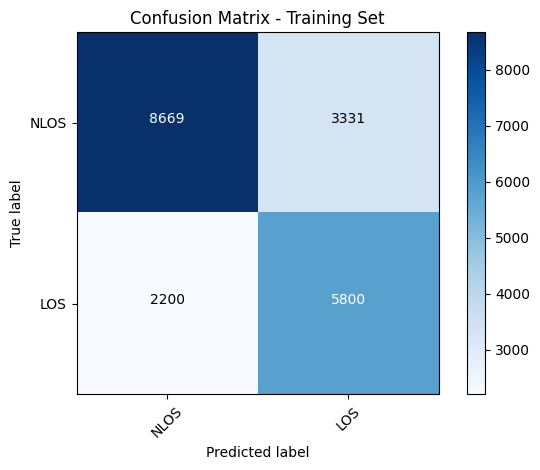

Confusion Matrix:
[[8669 3331]
 [2200 5800]]


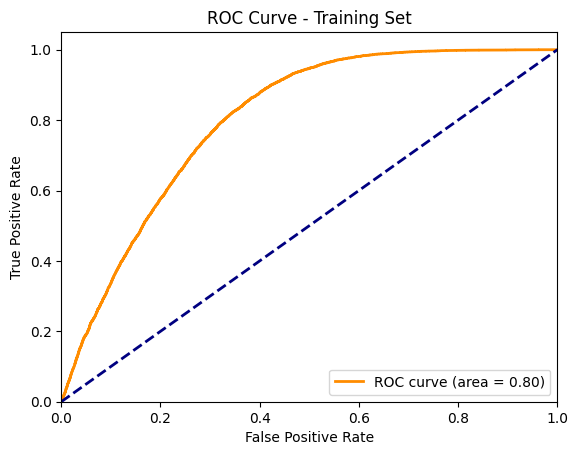

Metrics for Training Set:
Accuracy: 0.7235
Precision: 0.6352
Recall (Sensitivity): 0.7250
Specificity: 0.7224
F1 Score: 0.6771
ROC AUC: 0.8008
Log Loss: 0.5096


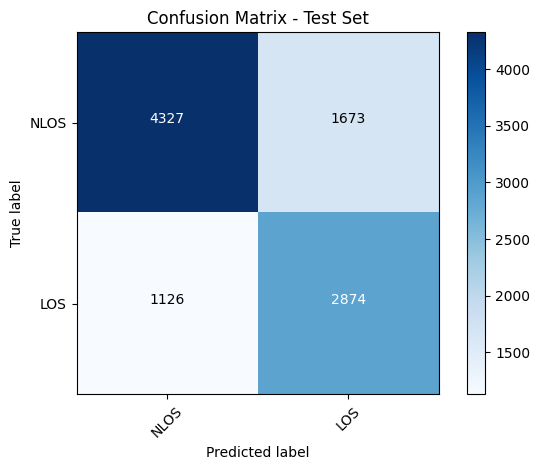

Confusion Matrix:
[[4327 1673]
 [1126 2874]]


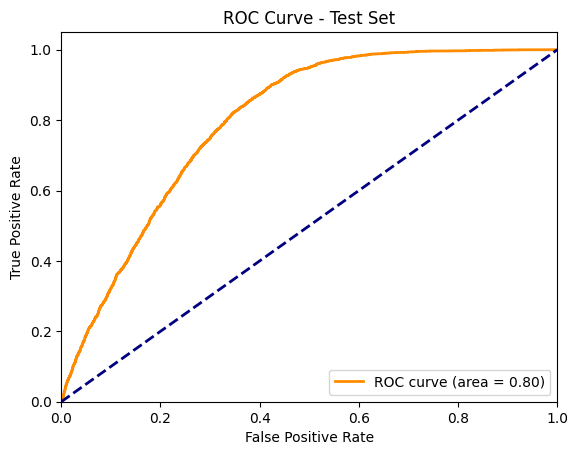

Metrics for Test Set:
Accuracy: 0.7201
Precision: 0.6321
Recall (Sensitivity): 0.7185
Specificity: 0.7212
F1 Score: 0.6725
ROC AUC: 0.7973
Log Loss: 0.5113


In [ ]:
# Concatenate full  the datasets in training and testing
# df_full = pd.concat([df_tdl_cdl, df_sionna_mimo])
# df_full_test = pd.concat([df_tdl_cdl_test, df_sionna_mimo_test])
df_full = df_tdl_cdl_siso
df_full_test = df_tdl_cdl_siso_test
# Preprocess the data
features, labels = preprocess_data(df_full)
features_test, labels_test = preprocess_data(df_full_test)
# Train the model and get predictions
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob, _ = train_mlp(features, labels, features_test, labels_test)

# Plot confusion matrix and ROC curve for training set
plot_confusion_matrix(y_train, y_train_pred, title='Confusion Matrix - Training Set')
plot_roc_curve(y_train, y_train_prob, title='ROC Curve - Training Set')

# Print metrics for training set
print("Metrics for Training Set:")
print_metrics(y_train, y_train_pred, y_train_prob)

# Plot confusion matrix and ROC curve for test set
plot_confusion_matrix(y_test, y_test_pred, title='Confusion Matrix - Test Set')
plot_roc_curve(y_test, y_test_prob, title='ROC Curve - Test Set')

# Print metrics for test set
print("Metrics for Test Set:")
print_metrics(y_test, y_test_pred, y_test_prob)


In [ ]:
print("TDL")
df_full = df_tdl_cdl_siso
df_full_test = df_tdl_cdl_siso_test
features, labels = preprocess_data(df_full)
features_test, labels_test = preprocess_data(df_full_test)
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob,mlp = train_mlp(features, labels, features_test, labels_test)
print("Metrics for Test Set, -3-20db:")
print_metrics(y_test, y_test_pred, y_test_prob)
df_full_test = df_tdl_cdl_0db_siso_test
features_test, labels_test = preprocess_data(df_full_test)
y_tests = labels_test
y_test_pred = mlp.predict(features_test)
y_test_prob = mlp.predict_proba(features_test)
print("Metrics for Test Set, 0db:")
print_metrics(y_test, y_test_pred, y_test_prob)
df_full_test = df_tdl_cdl_5db_siso_test
features_test, labels_test = preprocess_data(df_full_test)
y_tests = labels_test
y_test_pred = mlp.predict(features_test)
y_test_prob = mlp.predict_proba(features_test)
print("Metrics for Test Set, 5db:")
print_metrics(y_test, y_test_pred, y_test_prob)
df_full_test = df_tdl_cdl_10db_siso_test
features_test, labels_test = preprocess_data(df_full_test)
y_tests = labels_test
y_test_pred = mlp.predict(features_test)
y_test_prob = mlp.predict_proba(features_test)
print("Metrics for Test Set, 10db:")
print_metrics(y_test, y_test_pred, y_test_prob)
df_full_test = df_tdl_cdl_15db_siso_test
features_test, labels_test = preprocess_data(df_full_test)
y_tests = labels_test
y_test_pred = mlp.predict(features_test)
y_test_prob = mlp.predict_proba(features_test)
print("Metrics for Test Set, 15db:")
print_metrics(y_test, y_test_pred, y_test_prob)


TDL


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

ValueError: not enough values to unpack (expected 7, got 6)

In [ ]:

print("MIMO")
df_full = df_tdl_cdl_mimo
features, labels = preprocess_data(df_full)
df_full_test = df_tdl_cdl_mimo_test
features_test, labels_test = preprocess_data(df_full_test)
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_mlp(features, labels, features_test, labels_test)
print("Metrics for Test Set:")
print_metrics(y_test, y_test_pred, y_test_prob)
df_full_test = df_tdl_cdl_0db_mimo_test
features_test, labels_test = preprocess_data(df_full_test)
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_mlp(features, labels, features_test, labels_test)
print("Metrics for Test Set:")
print_metrics(y_test, y_test_pred, y_test_prob) 
df_full_test = df_tdl_cdl_5db_mimo_test
features_test, labels_test = preprocess_data(df_full_test)
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_mlp(features, labels, features_test, labels_test)
print("Metrics for Test Set:")
print_metrics(y_test, y_test_pred, y_test_prob)
df_full_test = df_tdl_cdl_10db_mimo_test
features_test, labels_test = preprocess_data(df_full_test)
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_mlp(features, labels, features_test, labels_test)
print("Metrics for Test Set:")
print_metrics(y_test, y_test_pred, y_test_prob)
df_full_test = df_tdl_cdl_15db_mimo_test
features_test, labels_test = preprocess_data(df_full_test)
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_mlp(features, labels, features_test, labels_test)
print("Metrics for Test Set:")
print_metrics(y_test, y_test_pred, y_test_prob)

TDL Dataset NLOS/LOS Classification
=======================================

In [ ]:
# Train the model and get predictions
features_tdl, labels_tdl = preprocess_data(df_tdl)
features_tdl_test, labels_tdl_test = preprocess_data(df_tdl_test)

y_tdl_train, y_tdl_train_pred, y_tdl_train_prob, y_tdl_test, y_tdl_test_pred, y_tdl_test_prob = train_mlp(features_tdl, labels_tdl, features_tdl_test, labels_tdl_test)

# Plot confusion matrix and ROC curve for tdl training set
plot_confusion_matrix(y_tdl_train, y_tdl_train_pred, title='Confusion Matrix - TDL Training Set')
plot_roc_curve(y_tdl_train, y_tdl_train_prob, title='ROC Curve - TDL Training Set')

# Print metrics for tdl training set
print("Metrics for TDL Training Set:")
print_metrics(y_tdl_train, y_tdl_train_pred, y_tdl_train_prob)

# Plot confusion matrix and ROC curve for tdl test set
plot_confusion_matrix(y_tdl_test, y_tdl_test_pred, title='Confusion Matrix - TDL Test Set')
plot_roc_curve(y_tdl_test, y_tdl_test_prob, title='ROC Curve - TDL Test Set')

# Print metrics for tdl test set
print("Metrics for TDL Test Set:")
print_metrics(y_tdl_test, y_tdl_test_pred, y_tdl_test_prob)

NameError: name 'df_tdl' is not defined

CDL Dataset NLOS/LOS Classification
=======================================

/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

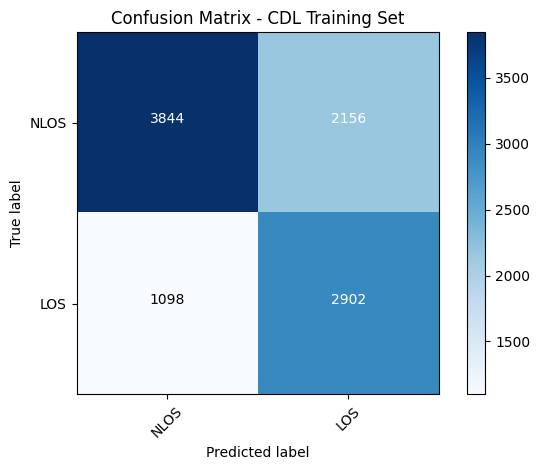

Confusion Matrix:
[[3844 2156]
 [1098 2902]]


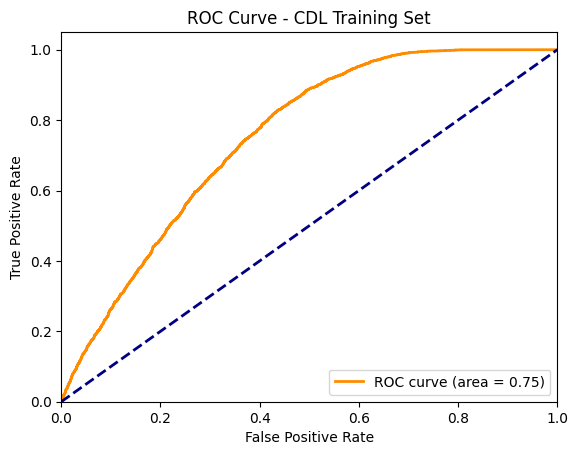

Metrics for CDL Training Set:
Accuracy: 0.6746
Precision: 0.5737
Recall (Sensitivity): 0.7255
Specificity: 0.6407
F1 Score: 0.6408
ROC AUC: 0.7499
Log Loss: 0.5529


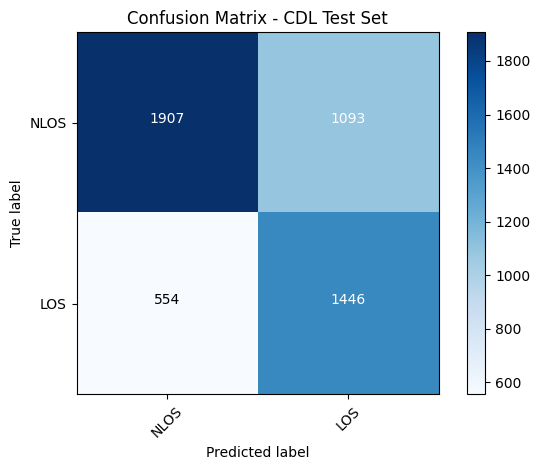

Confusion Matrix:
[[1907 1093]
 [ 554 1446]]


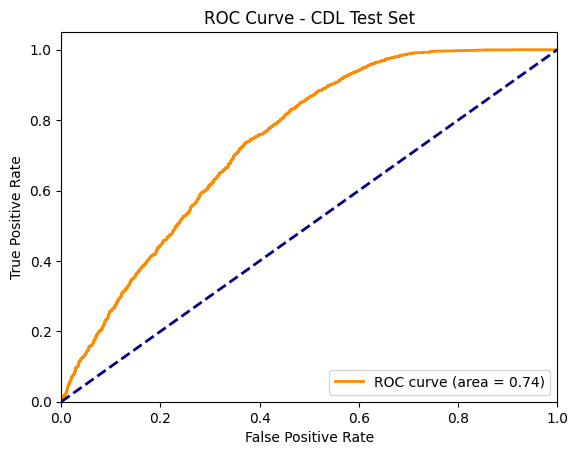

Metrics for CDL Test Set:
Accuracy: 0.6706
Precision: 0.5695
Recall (Sensitivity): 0.7230
Specificity: 0.6357
F1 Score: 0.6371
ROC AUC: 0.7392
Log Loss: 0.5612


In [ ]:
features_cdl, labels_cdl = preprocess_data(df_cdl)
features_cdl_test, labels_cdl_test = preprocess_data(df_cdl_test)

y_cdl_train, y_cdl_train_pred, y_cdl_train_prob, y_cdl_test, y_cdl_test_pred, y_cdl_test_prob = train_mlp(features_cdl, labels_cdl, features_cdl_test, labels_cdl_test)

# Plot confusion matrix and ROC curve for cdl training set
plot_confusion_matrix(y_cdl_train, y_cdl_train_pred, title='Confusion Matrix - CDL Training Set')
plot_roc_curve(y_cdl_train, y_cdl_train_prob, title='ROC Curve - CDL Training Set')

# Print metrics for cdl training set
print("Metrics for CDL Training Set:")
print_metrics(y_cdl_train, y_cdl_train_pred, y_cdl_train_prob)

# Plot confusion matrix and ROC curve for cdl test set
plot_confusion_matrix(y_cdl_test, y_cdl_test_pred, title='Confusion Matrix - CDL Test Set')
plot_roc_curve(y_cdl_test, y_cdl_test_prob, title='ROC Curve - CDL Test Set')

# Print metrics for cdl test set
print("Metrics for CDL Test Set:")
print_metrics(y_cdl_test, y_cdl_test_pred, y_cdl_test_prob)


SIONNA MIMO Dataset NLOS/LOS Classification
=======================================

/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

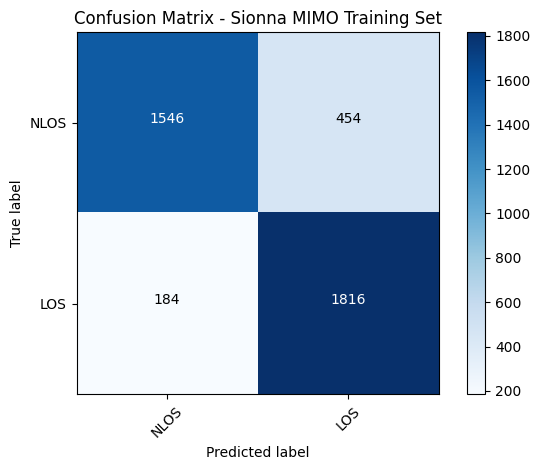

Confusion Matrix:
[[1546  454]
 [ 184 1816]]


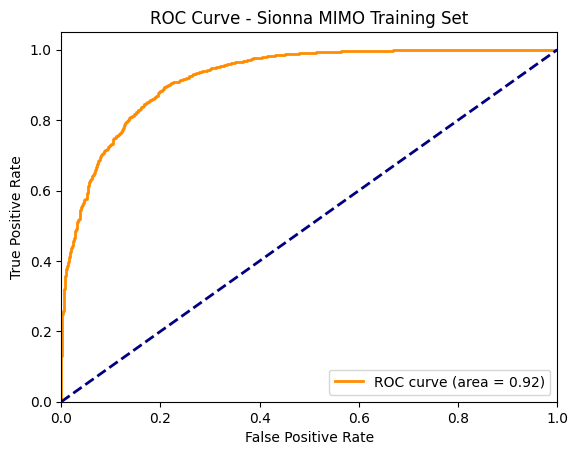

Metrics for Sionna MIMO Training Set:


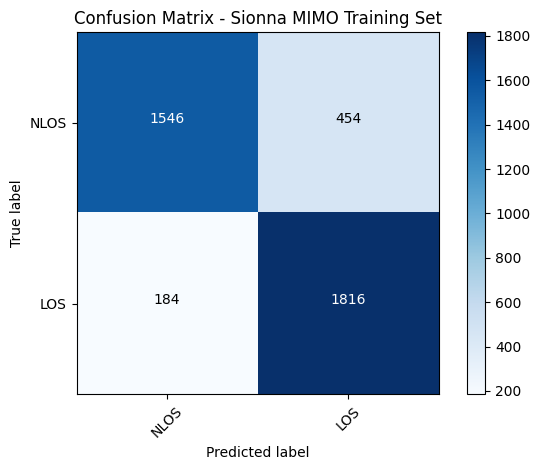

Confusion Matrix:
[[1546  454]
 [ 184 1816]]


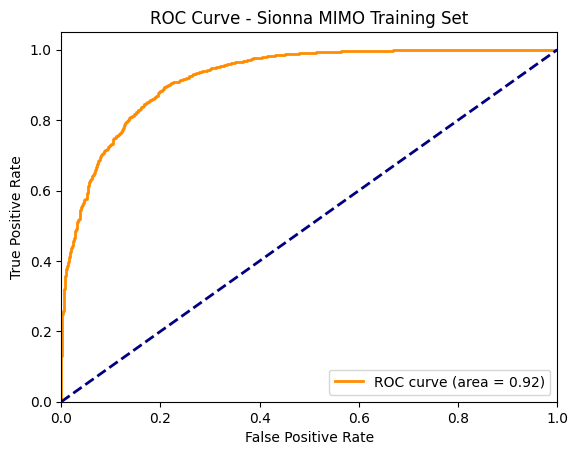

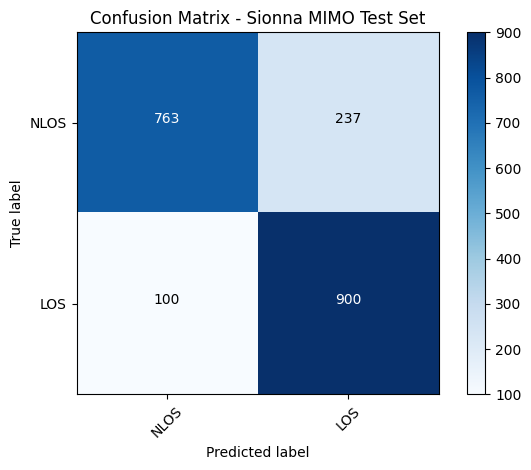

Confusion Matrix:
[[763 237]
 [100 900]]


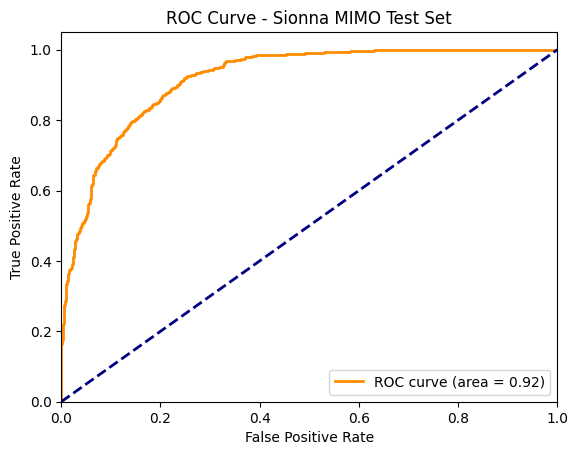

Metrics for Sionna MIMO Test Set:
Accuracy: 0.8315
Precision: 0.7916
Recall (Sensitivity): 0.9000
Specificity: 0.7630
F1 Score: 0.8423
ROC AUC: 0.9177
Log Loss: 0.3567


In [ ]:
# Train the model and get predictions
features_sionna_mimo, labels_sionna_mimo = preprocess_data(df_sionna_mimo)
features_sionna_mimo_test, labels_sionna_mimo_test = preprocess_data(df_sionna_mimo_test)

y_sionna_mimo_train, y_sionna_mimo_train_pred, y_sionna_mimo_train_prob, y_sionna_mimo_test, y_sionna_mimo_test_pred, y_sionna_mimo_test_prob = train_mlp(features_sionna_mimo, labels_sionna_mimo, features_sionna_mimo_test, labels_sionna_mimo_test)
# Plot confusion matrix and ROC curve for sionna mimo training set
plot_confusion_matrix(y_sionna_mimo_train, y_sionna_mimo_train_pred, title='Confusion Matrix - Sionna MIMO Training Set')
plot_roc_curve(y_sionna_mimo_train, y_sionna_mimo_train_prob, title='ROC Curve - Sionna MIMO Training Set')  

# Print metrics for sionna mimo training set
print("Metrics for Sionna MIMO Training Set:")
plot_confusion_matrix(y_sionna_mimo_train, y_sionna_mimo_train_pred, title='Confusion Matrix - Sionna MIMO Training Set')
plot_roc_curve(y_sionna_mimo_train, y_sionna_mimo_train_prob, title='ROC Curve - Sionna MIMO Training Set')

# Plot confusion matrix and ROC curve for sionna mimo test set
plot_confusion_matrix(y_sionna_mimo_test, y_sionna_mimo_test_pred, title='Confusion Matrix - Sionna MIMO Test Set')
plot_roc_curve(y_sionna_mimo_test, y_sionna_mimo_test_prob, title='ROC Curve - Sionna MIMO Test Set')

# Print metrics for sionna mimo test set
print("Metrics for Sionna MIMO Test Set:")
print_metrics(y_sionna_mimo_test, y_sionna_mimo_test_pred, y_sionna_mimo_test_prob)

SIONNA SISO Dataset NLOS/LOS Classification
=======================================

/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

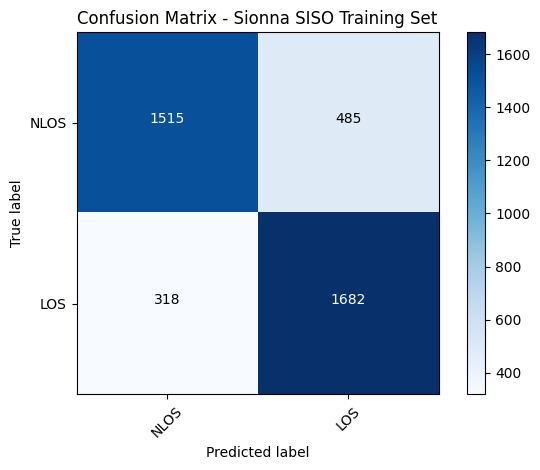

Confusion Matrix:
[[1515  485]
 [ 318 1682]]


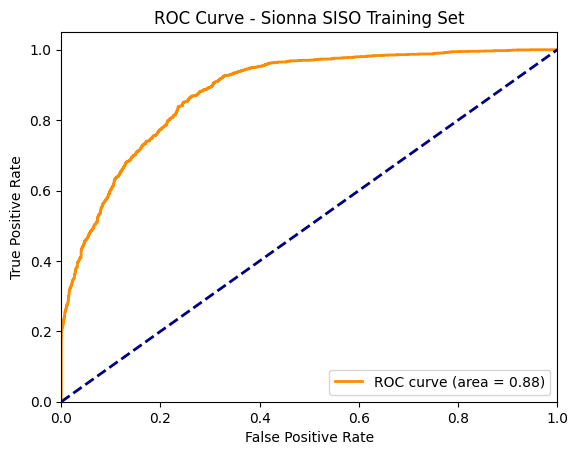

Metrics for Sionna SISO Training Set:


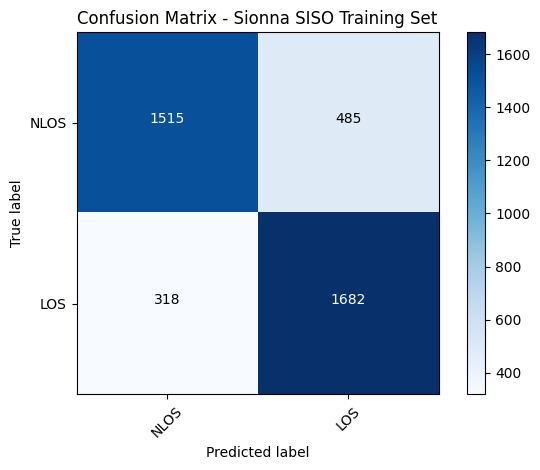

Confusion Matrix:
[[1515  485]
 [ 318 1682]]


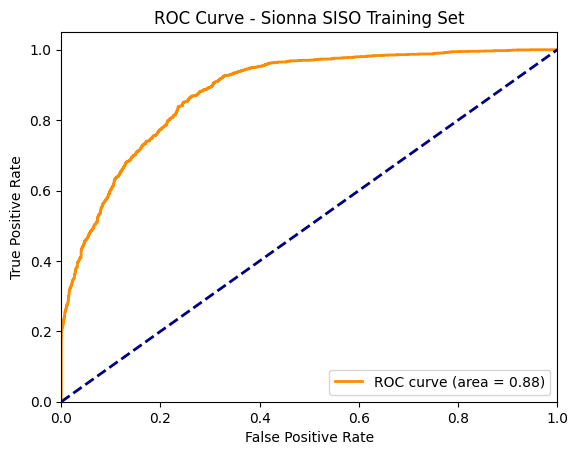

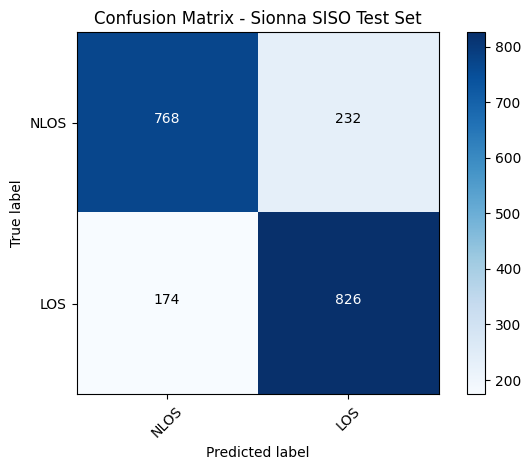

Confusion Matrix:
[[768 232]
 [174 826]]


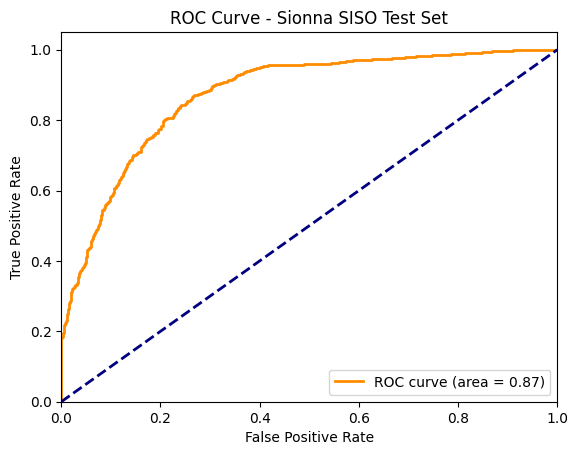

Metrics for Sionna SISO Test Set:
Accuracy: 0.7970
Precision: 0.7807
Recall (Sensitivity): 0.8260
Specificity: 0.7680
F1 Score: 0.8027
ROC AUC: 0.8733
Log Loss: 0.4389


In [ ]:
# Train the model and get predictions
features_sionna_siso, labels_sionna_siso = preprocess_data(df_sionna_siso)
features_sionna_siso_test, labels_sionna_siso_test = preprocess_data(df_sionna_siso_test)

y_sionna_siso_train, y_sionna_siso_train_pred, y_sionna_siso_train_prob, y_sionna_siso_test, y_sionna_siso_test_pred, y_sionna_siso_test_prob = train_mlp(features_sionna_siso, labels_sionna_siso, features_sionna_siso_test, labels_sionna_siso_test)
# Plot confusion matrix and ROC curve for sionna mimo training set
plot_confusion_matrix(y_sionna_siso_train, y_sionna_siso_train_pred, title='Confusion Matrix - Sionna SISO Training Set')
plot_roc_curve(y_sionna_siso_train, y_sionna_siso_train_prob, title='ROC Curve - Sionna SISO Training Set')
# Print metrics for sionna mimo training set
print("Metrics for Sionna SISO Training Set:")
plot_confusion_matrix(y_sionna_siso_train, y_sionna_siso_train_pred, title='Confusion Matrix - Sionna SISO Training Set')
plot_roc_curve(y_sionna_siso_train, y_sionna_siso_train_prob, title='ROC Curve - Sionna SISO Training Set')

# Plot confusion matrix and ROC curve for sionna mimo test set
plot_confusion_matrix(y_sionna_siso_test, y_sionna_siso_test_pred, title='Confusion Matrix - Sionna SISO Test Set')
plot_roc_curve(y_sionna_siso_test, y_sionna_siso_test_prob, title='ROC Curve - Sionna SISO Test Set')
# Print metrics for sionna mimo test set
print("Metrics for Sionna SISO Test Set:")
print_metrics(y_sionna_siso_test, y_sionna_siso_test_pred, y_sionna_siso_test_prob)

In [ ]:
# # Preprocess the data
# y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob = train_mlp(features, labels, features_test, labels_test)

# # Plot confusion matrix and ROC curve for training set
# plot_confusion_matrix(y_train, y_train_pred, title='Confusion Matrix - Training Set')
# plot_roc_curve(y_train, y_train_prob, title='ROC Curve - Training Set')

# # Print metrics for training set
# print("Metrics for Training Set:")
# print_metrics(y_train, y_train_pred, y_train_prob)

# # Plot confusion matrix and ROC curve for test set
# plot_confusion_matrix(y_test, y_test_pred, title='Confusion Matrix - Test Set')
# plot_roc_curve(y_test, y_test_prob, title='ROC Curve - Test Set')

# # Print metrics for test set
# print("Metrics for Test Set:")
# print_metrics(y_test, y_test_pred, y_test_prob)